# Natural-image export for the drift model, straight from the database

This notebook builds the **drift-model input** (the folder tree the Sinz-lab `drift-models` code reads, one folder per
recording) for **all 11 curated mice** of Leon Kremers' natural-image experiment. Everything comes from the lab's
DataJoint database. The only exception is the stimulus images, which are files (see section 9).

It repeats Leon's export step by step (`helpers/pipeline_blocks.inception_export_v2` in `LeonKremers/adamacs`, run from
`notebooks/62_Leon_NaturalImages_Export.ipynb`). Where the lab fixed something since his export, the notebook uses
the fix and says so:

| what | Leon's export | here |
|---|---|---|
| responses, trials, image ids, unit ids | DataJoint | the same tables, **identical values** (section 13) |
| cross-session ids (`global_unit_ids`) | `Segmentation.Mask.roi_group` at export time | the CellReg run in `roselab_cell_registration` that his export used (section 6) |
| camera frame times | gate rule (`aux_cam`, `main_track_gate`) | `roselab_facemap.FrameSync`: stored per-frame events, else the start anchor or gate rule chosen by the trigger count (section 7.2) |
| pupil size and centre | ellipse through the DLC pupil markers + set-10 outlier rejection | image rim fit `PupilEllipseFitting` set **12** (v4.1) with its outlier rejection; eye angles added |
| glint | DLC `IR` marker, likelihood ≥ 0.9 | `CorrectedGlint` set **3** (image detection, DLC fallback; re-detections excluded) |
| face motion | Leon's `*_face_cam_concatenate_proc.npy` files | `roselab_facemap.FacialSignal` (the same runs; 15 segments corrected by 4 frames) |
| running speed | 2.5-s box **ahead** of each sample, deg/s | 2.5-s box **centred** on each sample, cm/s |
| behaviour window | stimulus frames `[on, on+n)` | the response window `[on+3, on+3+n)` (settable) |
| ROI QC | none | flag `roi_qc_rejected` per neuron (no neuron is dropped) |

**Who this is for.** People who know Python and the drift model, but not our database. Every query is plain
DataJoint (restrict `&`, join `*`, `fetch`), and every table is introduced where it is first used.

**Contents**

1. Connect (only `pip install datajoint`)
2. The database in one picture
3. Which mice and recordings
4. Which cells: curation, soma masks, ROI QC
5. Trials: 2P frame clock, stimulus events, image ids, tiers
6. Responses
7. The same cell across days: CellReg
8. Behaviour: running, camera clock, pupil and glint, face motion
9. Stimulus images (files)
10. Statistics and the folder tree
11. Export one recording, step by step
12. Export a whole mouse; tracked neurons
13. Cross-check against Leon's export
14. Export all 11 mice
15. What is not in the database
16. Differences from Leon's export, in one table

## 1. Connect

You need Python ≥ 3.9 and

```bash
pip install datajoint numpy pandas matplotlib pillow
```

No lab code is needed. DataJoint reads the connection from environment variables (or from a `dj_local_conf.json`
in the working directory):

```bash
export DJ_HOST=<database host>      # ask the Rose lab
export DJ_USER=<your user>
export DJ_PASS=<your password>
```

Two settings matter:

* **Virtual modules.** `dj.create_virtual_module(name, "roselab_<schema>")` builds Python classes for the tables that
  exist on the server. It never creates or changes anything. This is the simplest way to read any DataJoint database.
* **Read-only session.** `SET SESSION transaction_read_only = 1` makes the server refuse every write from this
  connection. Keep it; you only need to read.

In [1]:
# DEF: connection and settings
import os, json, glob, time, logging, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import datajoint as dj
dj.logger.setLevel(logging.WARNING)            # after the import: keeps connection details out of printed output

for _c in ("dj_local_conf.json", "../dj_local_conf.json", os.path.expanduser("~/adamacs/dj_local_conf.json")):
    if os.path.exists(_c) and not os.environ.get("DJ_HOST"):
        dj.config.load(_c); break
dj.config["database.use_tls"] = os.environ.get("DJ_TLS", "0") == "1"
dj.config["display.limit"] = 6
dj.conn().query("SET SESSION transaction_read_only = 1")
assert dj.conn().query("SELECT @@transaction_read_only").fetchone()[0] == 1, "session must be read-only"

def schema(name):
    "A read-only Python module for one database schema (roselab_<name>)."
    return dj.create_virtual_module(name, "roselab_" + name, create_schema=False, create_tables=False)

subject, session, scan, imaging = schema("subject"), schema("session"), schema("scan"), schema("imaging")
event, behavior, pupil, facemap = schema("event"), schema("behavior"), schema("pupil_tracking"), schema("facemap")
cellreg = schema("cell_registration")
print("datajoint", dj.__version__, "| read-only session: yes")

datajoint 0.14.8 | read-only session: yes


## 2. The database in one picture

Every table is keyed by its parents' keys. The ones this export reads:

```
subject.Subject (subject)                                   the mouse, e.g. 'ROS-1841'
 └ session.Session (session_id)                             one imaging day;  session.SessionSameSite.same_site_id = the imaging site
    └ scan.Scan (session_id, scan_id)                       one recording;  scan_notes says the stimulus, e.g. 'Natural Images'
       ├ event.BehaviorRecording                            recording_notes says the behavioural stage, e.g. 'baseline'
       ├ event.Event (…, event_type, event_start_time)      every timed event: 2P frames, camera triggers, stimuli
       ├ behavior.TreadmillRecording.Channel                the running wheel ('wheel_pos')
       ├ imaging.Curation (paramset_idx, curation_id)       one suite2p segmentation (paramset 10) and its curation
       │  ├ imaging.Segmentation.Mask (mask)                each ROI: centre, pixels, roi_group
       │  ├ imaging.MaskClassification.MaskType             'soma' or not
       │  ├ imaging.RoiQC.Rejected                          ROIs that failed a QC criterion
       │  └ imaging.Activity.Trace (extraction_method)      deconvolved activity per ROI ('suite2p_deconvolution' = OASIS)
       ├ pupil_tracking.PupilEllipseFitting (parameter_id)  per-frame pupil ellipse of the eye camera
       ├ pupil_tracking.CorrectedGlint (glint_param_id)     per-frame corneal reflection
       └ facemap.FacemapTask.Video → FacialSignal.Trace     face-motion SVDs, FrameSync = camera frame times
cell_registration.CellRegRun → CellRegResult.Cell / .Member  CellReg across days: mask ↔ cell_index
```

You can print any table's columns with `.heading`, or look at a few rows by typing its name.

In [2]:
imaging.Segmentation.Mask.heading

session_id           : varchar(12)                  # 
scan_id              : varchar(12)                  # 
paramset_idx         : smallint                     # 
curation_id          : int                          # 
mask                 : smallint                     # 
---
roi_group            : smallint                     # chronic recording same-cell-id. Defaults to 0. #TR23
segmentation_channel : tinyint                      # 0-based indexing
mask_npix            : int                          # number of pixels in ROIs
mask_center_x        : int                          # center x coordinate in pixel
mask_center_y        : int                          # center y coordinate in pixel
mask_center_z        : int                          # center z coordinate in pixel
mask_xpix            : longblob                     # x coordinates in pixels
mask_ypix            : longblob                     # y coordinates in pixels
mask_zpix            : longblob                     # z coo

## 3. Which mice and recordings

The cohort is 11 mice, each imaged at one site (a `same_site_id`, the session id of the site's first day). Leon
selects a site's recordings with three text filters, and so do we:

* `scan_notes` contains `images` (natural-image recordings) and not `Do not use!`;
* `recording_notes` contains `baseline` (the behavioural stage of this experiment).

The list of the 11 sites is the only input that is not a database query: the database does not mark which mice form
the curated cohort.

In [3]:
# DEF: cohort and recording selection
SITES = {                       # mouse -> imaging site (same_site_id), Leon's 62_Leon_NaturalImages_Export + ROS-2356/2357/2359
    "ROS-1841": "sess9FOTVMAL", "ROS-1881": "sess9FPXNI8U", "ROS-1907": "sess9FQ644X9", "ROS-1912": "sess9FQ64WDC",
    "ROS-1985": "sess9FS1DQX9", "ROS-2209": "sess9FXCKHW1", "ROS-2210": "sess9FXCJN0G", "ROS-2328": "sess9G1EB7EE",
    "ROS-2356": "sess9G2BR5GW", "ROS-2357": "sess9G2MHBXT", "ROS-2359": "sess9G2BRX9J",
}

def recordings_of(mouse):
    "The natural-image baseline recordings of one mouse's site, in recording order (one dict per recording)."
    site_sessions = session.SessionSameSite & {"same_site_id": SITES[mouse]}
    q = (session.Session * scan.Scan * event.BehaviorRecording & site_sessions
         & 'scan_notes LIKE "%images%"' & 'scan_notes NOT LIKE "%Do not use!%"'
         & 'recording_notes LIKE "%baseline%"')
    return q.fetch("session_id", "scan_id", "subject", "session_datetime", as_dict=True, order_by="session_datetime")

In [4]:
rows = []
for m in SITES:
    recs = recordings_of(m)
    rows.append(dict(mouse=m, site=SITES[m], n_recordings=len(recs), first=str(recs[0]["session_datetime"])[:10],
                     last=str(recs[-1]["session_datetime"])[:10]))
cohort = pd.DataFrame(rows).set_index("mouse"); cohort

,site,n_recordings,first,last
mouse,,,,
ROS-1841,sess9FOTVMAL,11,2024-07-01,2024-07-21
ROS-1881,sess9FPXNI8U,11,2024-09-05,2024-09-25
ROS-1907,sess9FQ644X9,11,2024-09-17,2024-10-07
ROS-1912,sess9FQ64WDC,11,2024-09-17,2024-10-07
ROS-1985,sess9FS1DQX9,7,2025-01-08,2025-01-20
ROS-2209,sess9FXCKHW1,11,2025-11-30,2025-12-20
ROS-2210,sess9FXCJN0G,11,2025-11-30,2025-12-20
ROS-2328,sess9G1EB7EE,11,2026-07-28,2026-08-17
ROS-2356,sess9G2BR5GW,11,2026-09-23,2026-10-13


ROS-1985 has 7 recordings; every other mouse has 11, one every second day. Each recording's key is
`(session_id, scan_id)`; we pass these dicts to every query below.

## 4. Which cells: curation, soma masks, ROI QC

**Curation.** A recording can be segmented more than once. `imaging.Curation` holds every result; `paramset_idx = 10`
is the lab's suite2p parameter set, and the **highest `curation_id`** is the latest curation. Always restrict both
`paramset_idx` and `curation_id`: below `Curation`, every table holds rows of every curation.

**Cells.** A neuron is an ROI (`mask`) of that curation whose `MaskClassification.MaskType.mask_type` is `soma`.
They are ordered by `mask` id, and that order is the neuron axis of every array in the export.

**ROI QC.** `imaging.RoiQC.Rejected` lists ROIs that fail a quality criterion (`empty_f`: the ROI is fully overlapped
and has no own pixels, so its trace is neuropil; `second_channel`). Leon's export keeps them. We keep them too, so
that the neuron axis stays his, and add a flag `meta/neurons/roi_qc_rejected.npy`.

In [5]:
# DEF: curation and cells
PARAMSET = 10

def latest_curation(rec):
    "Key of the latest curation (highest curation_id) of paramset 10 for one recording."
    key = {"session_id": rec["session_id"], "scan_id": rec["scan_id"]}
    cid = max((imaging.Curation & key & {"paramset_idx": PARAMSET}).fetch("curation_id"))
    return dict(key, paramset_idx=PARAMSET, curation_id=int(cid))

def soma_query(cur):
    return imaging.Segmentation.Mask * imaging.MaskClassification.MaskType & cur & 'mask_type = "soma"'

def cells_of(cur):
    "One row per soma ROI, ordered by mask id: mask, roi_group, ROI centre (px) and the ROI-QC flag."
    df = pd.DataFrame(soma_query(cur).fetch("mask", "roi_group", "mask_center_x", "mask_center_y",
                                            order_by="mask", as_dict=True))
    rejected = (dj.U("mask") & (imaging.RoiQC.Rejected & cur)).fetch("mask")
    df["roi_qc_rejected"] = df["mask"].isin(rejected)
    return df

In [6]:
rec0 = recordings_of("ROS-1841")[0]
cur0 = latest_curation(rec0); print(cur0)
cells0 = cells_of(cur0)
print(len(imaging.Segmentation.Mask & cur0), "ROIs,", len(cells0), "soma,", int(cells0.roi_qc_rejected.sum()), "rejected by ROI QC")
cells0.head()

{'session_id': 'sess9FOWAIBH', 'scan_id': 'scan9FOWAIBH', 'paramset_idx': 10, 'curation_id': 2}
1361 ROIs, 667 soma, 0 rejected by ROI QC


,mask,roi_group,mask_center_x,mask_center_y,roi_qc_rejected
0,0,0,159,355,False
1,1,1,315,423,False
2,2,2,447,71,False
3,3,3,67,423,False
4,4,4,267,167,False


## 5. Trials: 2P frame clock, stimulus events, image ids, tiers

All times live on one clock, the DAQ clock of the recording, in seconds. `event.Event` holds every timed event of a
recording; its `event_type` says what it is.

* **2P frames**: `event_type = 'bench2p_frames'`; `event_start_time` of frame i.
* **Images**: `event_type` starts with `Natural Image`, with start (image on) and end (image off) times. The text
  carries the image: `Natural Image:2269;Natural Images;0;10;…` (older mice) or
  `Natural Image:LSVRC2012_test_00002519.jpg;…` (ROS-2328 on). The **image id** is `2269`, or the 8 digits before
  `.jpg`.

Always restrict `event.Event` by `session_id` **and** `scan_id`: the table has about a billion rows, and its index starts
with `session_id`.

**From times to frames.** Each image onset and offset goes to the **nearest 2P frame** (on a tie, the earlier one).
`n = offset_frame − onset_frame + 2` of the **first** trial is the window length for the whole recording (18 frames
≈ 0.6 s here).

**Tiers** follow the image id: `test` ≤ 100 (100 images shown 10× in every session), `validation` 101–623 (shown once in
every session), `train` > 623 (each shown once in the whole experiment).

In [7]:
# DEF: trials
def frame_times_2p(rec):
    "DAQ time (s) of every 2P frame."
    q = event.Event & {"session_id": rec["session_id"], "scan_id": rec["scan_id"]} & {"event_type": "bench2p_frames"}
    return q.fetch("event_start_time", order_by="event_start_time").astype(float)

def image_number(frame_image_id):
    "'Natural Image:2269' -> 2269;  'Natural Image:LSVRC2012_test_00002519.jpg' -> 2519."
    s = frame_image_id.split(":", 1)[1]
    return int(s[-12:-4]) if s.endswith(".jpg") else int(s)

def nearest_frame(t, ft):
    "Index of the nearest 2P frame for each time t (the earlier frame on a tie; Leon's get_closest_timestamps)."
    i = np.clip(np.searchsorted(ft, t, side="left"), 1, len(ft) - 1)
    return np.where(ft[i] - t < t - ft[i - 1], i, i - 1)

def tier_of(image_id):
    return np.where(image_id <= 100, "test", np.where(image_id <= 623, "validation", "train"))

def image_trials(rec, ft):
    "One row per image presentation: id string, image number, tier, on/off time and frame."
    q = event.Event & {"session_id": rec["session_id"], "scan_id": rec["scan_id"]} & 'event_type LIKE "Natural Image%"'
    etype, t_on, t_off = q.fetch("event_type", "event_start_time", "event_end_time", order_by="event_start_time")
    tr = pd.DataFrame({"frame_image_id": [s.split(";")[0] for s in etype],
                       "t_on": t_on.astype(float), "t_off": t_off.astype(float)})
    tr["image_id"] = [image_number(s) for s in tr.frame_image_id]
    tr["tier"] = tier_of(tr.image_id.to_numpy())
    tr["on_frame"], tr["off_frame"] = nearest_frame(tr.t_on.to_numpy(), ft), nearest_frame(tr.t_off.to_numpy(), ft)
    return tr

In [8]:
ft0 = frame_times_2p(rec0)
tr0 = image_trials(rec0, ft0)
n0 = int(tr0.off_frame[0] - tr0.on_frame[0] + 2)
print(f"{len(ft0)} 2P frames at {1/np.median(np.diff(ft0)):.2f} Hz | {len(tr0)} trials | window n = {n0} frames")
print(tr0.tier.value_counts().to_dict(), "| test images:", tr0[tr0.tier == "test"].image_id.nunique(),
      "shown", tr0[tr0.tier == "test"].image_id.value_counts().unique(), "times")
tr0.head()

147300 2P frames at 29.93 Hz | 4900 trials | window n = 18 frames
{'train': 3377, 'test': 1000, 'validation': 523} | test images: 100 shown [10] times


,frame_image_id,t_on,t_off,image_id,tier,on_frame,off_frame
0,Natural Image:2269,7.29955,7.81495,2269,train,122,138
1,Natural Image:1972,8.19785,8.69910,1972,train,149,164
2,Natural Image:958,9.19800,9.69905,958,train,179,194
3,Natural Image:845,10.03095,10.53255,845,train,204,219
4,Natural Image:89,11.13855,11.86980,89,test,237,259


## 6. Responses

The response of a neuron to one image is the **mean deconvolved activity over `n` frames, starting 3 frames after the
onset frame**: frames `[on+3, on+3+n)`. The 3-frame offset (0.1 s) skips the delay of the calcium signal. The trace is
`imaging.Activity.Trace` with `extraction_method = 'suite2p_deconvolution'` (suite2p's OASIS), one row per ROI, fetched
in mask order. The values are the deconvolved activity in arbitrary units, as Leon exported them.

In [9]:
# DEF: responses
TRACE = "suite2p_deconvolution"
RESPONSE_OFFSET = 3              # frames between image onset and the response window

def activity(cur):
    "Deconvolved activity (n_neurons x n_frames) of the soma ROIs, in mask order."
    q = imaging.Activity.Trace & soma_query(cur).proj() & {"extraction_method": TRACE}
    return np.stack(q.fetch("activity_trace", order_by="mask")).astype(float)

def window_index(on_frame, offset, n):
    "Frame indices (n_trials x n) of each trial's window [on+offset, on+offset+n)."
    return np.asarray(on_frame)[:, None] + offset + np.arange(n)[None, :]

activity (667, 147300) | responses (4900, 667) | fraction of zero responses 0.236


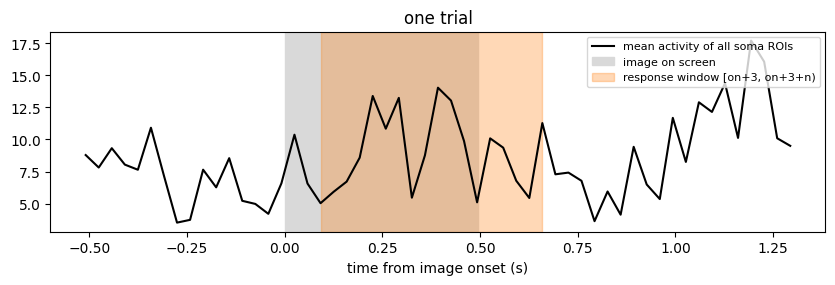

In [10]:
act0 = activity(cur0)
resp0 = act0[:, window_index(tr0.on_frame, RESPONSE_OFFSET, n0)].mean(-1).T      # trials x neurons
print("activity", act0.shape, "| responses", resp0.shape, "| fraction of zero responses", round(float((resp0 == 0).mean()), 3))

fig, ax = plt.subplots(figsize=(10, 2.6))
t = tr0.iloc[50]; f = np.arange(t.on_frame - 15, t.on_frame + 40)
ax.plot(ft0[f] - t.t_on, act0[:, f].mean(0), color="k", label="mean activity of all soma ROIs")
ax.axvspan(0, t.t_off - t.t_on, color="0.85", label="image on screen")
w = window_index([t.on_frame], RESPONSE_OFFSET, n0)[0]
ax.axvspan(ft0[w[0]] - t.t_on, ft0[w[-1]] - t.t_on, color="tab:orange", alpha=0.3, label="response window [on+3, on+3+n)")
ax.set_xlabel("time from image onset (s)"); ax.legend(fontsize=8, loc="upper right"); ax.set_title("one trial")
plt.show()

## 7. The same cell across days: CellReg

suite2p segments every recording on its own, so mask 17 on day 1 and mask 17 on day 3 are unrelated. **CellReg**
(Sheintuch et al. 2017) matches ROIs across the recordings of a site. The lab's runs are in
`roselab_cell_registration`:

| table | one row per | what |
|---|---|---|
| `CellRegRun` | CellReg run | subject, result file, number of sessions |
| `CellRegRun.Session` | recording (column) of a run | which curation the column is |
| `CellRegRun.UnresolvedColumn` | column that could not be tied to a curation | the reason |
| `CellRegResult.Cell` | registered cell (`cell_index`) | registered centroid (one position in the site's common frame), number of sessions present |
| `CellRegResult.Member` | cell × recording | the `mask` of this cell in that recording's curation |

**`global_unit_ids` = `cell_index`** of the run. A neuron with the same `cell_index` in two recordings is the same
cell. **`cell_motor_coordinates_aligned`** = the cell's registered centroid (`CellRegResult.Cell`), the same on every
day. **`cell_motor_coordinates`** = the ROI centre in this recording's own image (`Segmentation.Mask`).

**Which run.** A site has several runs (natural images, gratings, combined, re-runs). The export uses the newest run
whose result folder is `<site>_Natural Images_CR`. That is the run Leon's export used, for all 11 mice.

**Another curation.** Sometimes the run registered an older curation, and a later one has pixel-identical ROIs (only the
soma classification changed). This holds for every recording of ROS-2209 and ROS-2210 (curations of June 2026) and for
the last recording of ROS-2356 and of ROS-2359. `run_members` checks the pixels in the database and then uses the
run's members of the registered curation.

**Unresolved columns.** For 14 recordings the database could not tie the run's column to a curation (ROS-1841: 1,
ROS-1985: 2, ROS-2357: all 11; `CellRegRun.UnresolvedColumn` says why), so `CellRegResult.Member` has no rows for
them. There the export falls back to `Segmentation.Mask.roi_group`, the cross-session id stored on each ROI. It
checks first that `roi_group` carries this run's ids on the recordings where both exist (`global_id_source =
'roi_group'`). ROS-2357 has no such recording, so its ids cannot be checked inside the database
(`'roi_group_unverified'`); they equal Leon's exported ids (section 14). `roi_group` is a single
column that later runs can overwrite: for ROS-2356 and ROS-2359 it now holds the ids of a later run, so there the run
membership is the right source and `roi_group` is not.

In [11]:
# DEF: CellReg
def cellreg_run(mouse):
    "The newest '<site>_Natural Images_CR' CellReg run of the mouse (the run Leon's export used)."
    q = cellreg.CellRegRun & {"subject": mouse} & f'result_file LIKE "%{SITES[mouse]}_Natural Images_CR/%"'
    return q.fetch("cellreg_run_id", order_by="result_file_mtime DESC", limit=1)[0]

def same_masks(cur_a, cur_b):
    "True if every ROI of curation cur_a exists in cur_b with the same mask id and exactly the same pixels."
    get = lambda c: {r["mask"]: (r["mask_xpix"], r["mask_ypix"]) for r in
                     (imaging.Segmentation.Mask & c).fetch("mask", "mask_xpix", "mask_ypix", as_dict=True)}
    a, b = get(cur_a), get(cur_b)
    return all(k in b and np.array_equal(v[0], b[k][0]) and np.array_equal(v[1], b[k][1]) for k, v in a.items())

def run_members(run_id, cur):
    '''(mask -> cell_index, source) of the run for this curation. If the run registered another curation of the same
    recording whose ROIs are pixel-identical (only the soma classification changed), its members are used.'''
    member = cellreg.CellRegResult.Member & {"cellreg_run_id": run_id} & cur
    if len(member):
        return dict(zip(*member.fetch("mask", "cell_index"))), "cellreg_member"
    rec = {k: cur[k] for k in ("session_id", "scan_id", "paramset_idx")}
    for c in (cellreg.CellRegRun.Session & {"cellreg_run_id": run_id} & rec).fetch("curation_id"):
        other = dict(rec, curation_id=int(c))
        if same_masks(cur, other):
            m = cellreg.CellRegResult.Member & {"cellreg_run_id": run_id} & other
            return dict(zip(*m.fetch("mask", "cell_index"))), f"cellreg_member (curation {int(c)}, identical ROIs)"
    return None, None

def global_ids(run_id, cur, cells, roi_group_verified=None):
    '''cell_index (global id) and registered centroid of every neuron, and where the id came from:
    'cellreg_member' (also of a pixel-identical curation), 'roi_group' (checked against the run's members) or
    'roi_group_unverified' (the run has no resolved column to check against). Neurons without a cell get -1 and NaN.'''
    lookup, source = run_members(run_id, cur)
    if lookup is not None:
        gid = np.array([lookup.get(k, -1) for k in cells["mask"]])
    else:                                   # unresolved column: fall back to roi_group
        if roi_group_verified is False:
            raise ValueError(f"{cur['scan_id']}: no CellReg members, and roi_group does not carry run {run_id[:12]}")
        gid = cells["roi_group"].to_numpy().astype(int)
        source = "roi_group" if roi_group_verified else "roi_group_unverified"
    cell = cellreg.CellRegResult.Cell & {"cellreg_run_id": run_id}
    ci, x, y = cell.fetch("cell_index", "centroid_x_registered", "centroid_y_registered")
    xy = dict(zip(ci, zip(x, y)))
    aligned = np.array([xy.get(g, (np.nan, np.nan)) for g in gid], float)
    return gid, aligned, source

def roi_group_carries_run(run_id, curations):
    '''True if roi_group == cell_index for every ROI of every curation where the run has members; False if any
    differs; None if the run has no members in these curations (nothing to check against).'''
    n_checked = 0
    for cur in curations:
        member = cellreg.CellRegResult.Member & {"cellreg_run_id": run_id} & cur
        if not len(member):
            continue
        m, ci = member.fetch("mask", "cell_index")
        rg = dict(zip(*(imaging.Segmentation.Mask & cur).fetch("mask", "roi_group")))
        if any(rg[a] != b for a, b in zip(m, ci)):
            return False
        n_checked += 1
    return True if n_checked else None

In [12]:
run0 = cellreg_run("ROS-1841")
display((cellreg.CellRegRun & {"cellreg_run_id": run0}).proj("subject", "n_sessions", "result_file", "cellreg_paramset_id"))
display((cellreg.CellRegRun.UnresolvedColumn & {"cellreg_run_id": run0}).proj("n_masks_cellreg", "reason"))
gid0, aligned0, src0 = global_ids(run0, cur0, cells0)
print(f"{src0}: {int((gid0 >= 0).sum())} of {len(gid0)} neurons have a cell_index; first ids {gid0[:6]}")

cellreg_run_id first 40 hex chars of result_file_sha256,cellreg_paramset_id human-readable slug,subject,result_file canonical path; copies live in .Copy,n_sessions
8d7f5e3cb43e4550332e27261c0b1e068fd3c7b9,prob_transrot_p0.3_3589a7f7,ROS-1841,/datajoint-data/data/leonk/analysis/cellreg/LE_ROS-1841_sess9FOTVMAL_Natural Images_CR/Results/cellRegistered_20260128_165905.mat,11


cellreg_run_id first 40 hex chars of result_file_sha256,column_index,n_masks_cellreg,reason
8d7f5e3cb43e4550332e27261c0b1e068fd3c7b9,8,1280,"no curation of scan9FP5TKME has a mask count matching the file's 1280 centroids for this column, so the segmentation this run used is not in the database"


cellreg_member: 667 of 667 neurons have a cell_index; first ids [0 1 2 3 4 5]


## 8. Behaviour

The behaviour vector of a trial has 24 columns, in Leon's order (the model reads columns 0–2):

| column | name | unit | source table |
|---|---|---|---|
| 0 | `running_speed` | cm/s | `behavior.TreadmillRecording.Channel` (`wheel_pos`) |
| 1 | `pupil_size` | camera px | `pupil_tracking.PupilEllipseFitting` set 12 (`diameter`) |
| 2 | `pupil_size_derivative` | px per camera frame | the same, frame-to-frame difference |
| 3–12 | `face_movie_SVD_component_0` … `_9` | a.u. | `facemap.FacialSignal.Trace.mov_svd` |
| 13–22 | `face_motion_SVD_component_0` … `_9` | a.u. | `facemap.FacialSignal.Trace.mot_svd` |
| 23 | `face_motion_energy` | a.u. | `facemap.FacialSignal.Trace.motion_energy` |

`pupil_center` holds the **pupil–glint vector** (x, y) in camera px, which the model uses for gaze.

Each signal has its own clock. The treadmill is sampled at 2 kHz on the DAQ clock; the eye/face camera runs at 60 Hz
and its frames must first be given DAQ times (8.2). Then every signal is averaged into 2P frames, and each trial takes
the mean over its window. **The behaviour window is the response window** `[on+3, on+3+n)`, so that behaviour and
response describe the same moments. Leon used `[on, on+n)`; set `BEHAVIOR_OFFSET = 0` to reproduce that.

### 8.1 Running speed

`wheel_pos` is the wheel's angle sensor (a voltage). Angle = `(raw − min) / max × 360`°, unwrapped. Speed = the time
derivative (on a 100 Hz copy) × 59.84 cm / 360° (the wheel circumference), smoothed with a **2.5-s box centred** on
each sample, read at each 2P frame time. Leon used the same 2.5-s box but placed it ahead of each sample, which
delays running by 1.25 s, and reported deg/s (6.0× our cm/s).

In [13]:
# DEF: running
BEHAVIOR_OFFSET = 3
WHEEL_CM_PER_DEG = 59.84 / 360.0
RUNNING_BOX_S = 2.5

def running_speed(rec, ft):
    "Running speed (cm/s) at every 2P frame time."
    q = behavior.TreadmillRecording.Channel & {"session_id": rec["session_id"], "scan_id": rec["scan_id"]} & {"channel_name": "wheel_pos"}
    t, raw = q.fetch1("time", "data")
    t, raw = np.asarray(t, float).ravel(), np.asarray(raw, float).ravel()
    angle = np.abs(np.degrees(np.unwrap(np.radians((raw - raw.min()) / raw.max() * 360))))
    t100, a100 = t[::20], angle[::20]                                   # 2 kHz -> 100 Hz
    v = np.gradient(a100, t100) * WHEEL_CM_PER_DEG
    k = int(round(RUNNING_BOX_S / np.median(np.diff(t100)))) | 1         # odd box length, centred
    return np.interp(ft, t100, np.convolve(v, np.ones(k) / k, mode="same"))

### 8.2 Camera frame times

The face camera is triggered at 60 Hz (`event_type = 'aux_cam'`), from before the recording gate (`main_track_gate`)
opens until after it closes; the video saves only some of these triggers. `roselab_facemap.FrameSync` stores four ways
to give each video frame a DAQ time, one row per method and FaceMap segment:

| `sync_method` | rule |
|---|---|
| `camera_frames` | stored per-frame events (`bench2p_face_frames`), one per saved frame: exact, where they exist and match the video |
| `gate_rule` | the last *n* triggers inside the gate (the video ends at the gate end; about 121 triggers at the start are not saved) |
| `start_anchored` | frame *i* = trigger 121 + *i* after the gate opens |
| `aux_cam_first_n` | Leon's original rule (the first *n* triggers): 2.9–6 s early, for reproducing old results only |

**The rule:** `camera_frames` if its `count_status` is `exact`; else `start_anchored` if the number of unsaved in-gate
triggers (`n_unsaved` of the `gate_rule` row) is outside 121 ± 5; else `gate_rule`. Where the count is off, the
video does not end at the gate end and the gate rule is off by up to 0.73 s; this affects three recordings of the
export (scan9FPZHKKB, scan9FQ1UYJD, scan9FQACAG8).

`frame_times` are per FaceMap row. In 15 segments (ROS-1912, ROS-2356) Leon's FaceMap rows are shifted by 4 video
frames (`FacemapProcessing.Segment.video_frame_offset`, measured against DLC face markers); the FrameSync times
already include that shift. The pupil fit is per video frame, so for it we undo the shift: video frame
`r + video_frame_offset` has the time of row `r`.

In [14]:
# DEF: camera clock
FACEMAP_PARAMSET, FACEMAP_LABEL = "leon_site_concat_2026", "images"   # Leon's site run (one SVD basis per site)
UNSAVED_TRIGGERS, UNSAVED_TOLERANCE = 121, 5

def face_segment(rec):
    "Key (facemap_task_id, segment_index) of this recording in Leon's site FaceMap run."
    q = facemap.FacemapTask * facemap.FacemapTask.Video & {"session_id": rec["session_id"], "scan_id": rec["scan_id"]} \
        & {"facemap_paramset": FACEMAP_PARAMSET, "task_label": FACEMAP_LABEL}
    return q.proj().fetch1()

def choose_sync_method(rows):
    if rows["camera_frames"]["count_status"] == "exact":
        return "camera_frames"
    n_unsaved = rows["gate_rule"]["n_unsaved"]
    if n_unsaved is None or abs(int(n_unsaved) - UNSAVED_TRIGGERS) > UNSAVED_TOLERANCE:
        return "start_anchored"
    return "gate_rule"

def camera_times(seg):
    "DAQ time of every FaceMap row and of every video frame, plus the method used (NaN = no time)."
    rows = {r["sync_method"]: r for r in (facemap.FrameSync & seg).fetch(as_dict=True)}
    method = choose_sync_method(rows)
    row_t = np.asarray(rows[method]["frame_times"], float)
    s = (facemap.FacemapProcessing.Segment & seg).fetch1()
    video_t = np.full(int(s["n_frames_video"]), np.nan)
    v = np.arange(len(row_t)) + int(s["video_frame_offset"])
    ok = (v >= 0) & (v < len(video_t)); video_t[v[ok]] = row_t[ok]
    info = dict(sync_method=method, n_unsaved=rows["gate_rule"]["n_unsaved"], video_frame_offset=int(s["video_frame_offset"]),
                facemap_task_id=seg["facemap_task_id"], segment_index=int(seg["segment_index"]))
    return row_t, video_t, info

def to_2p(x, t, ft):
    '''Mean of the camera samples x (n, or n x k) whose time t falls into each 2P frame [ft[i], ft[i+1]);
    2P frames without a sample take the previous frame's value (Leon's binning).'''
    x = np.asarray(x, float)
    good = np.isfinite(t) & (np.isfinite(x) if x.ndim == 1 else np.isfinite(x).all(1))
    b = np.searchsorted(ft, t[good], side="right") - 1
    inside = (b >= 0) & (b < len(ft)); b, xs = b[inside], x[good][inside]
    count = np.bincount(b, minlength=len(ft)); has = count > 0
    if not has.any():                                    # no usable sample at all (e.g. no glint): all NaN
        return np.full((len(ft),) + x.shape[1:], np.nan)
    src = np.maximum.accumulate(np.where(has, np.arange(len(ft)), -1)); src[src < 0] = np.argmax(has)
    if xs.ndim == 1:
        return (np.bincount(b, xs, len(ft)) / np.maximum(count, 1))[src]
    return np.stack([np.bincount(b, xs[:, j], len(ft)) / np.maximum(count, 1) for j in range(xs.shape[1])], 1)[src]

In [15]:
seg0 = face_segment(rec0)
display(facemap.FrameSync & seg0)
row_t0, video_t0, cam0 = camera_times(seg0); print(cam0)

"facemap_task_id task_id(paramset, ordered manifest, run_identity)",segment_index 0-based position in the concatenation (0 for per-video runs),sync_method,camera_event_type e.g. 'bench2p_face_frames' or 'aux_cam',n_events events the method drew from (see sync_description),n_unsaved in-gate triggers minus video frames (~121 normally),count_status,n_frames_untimed rows without a time (NaN in frame_times),"frame_times [n_frames] float64 s, NaN where untimed; NULL if no times",first_frame_s
3d5d1e1b01c4,0,aux_cam_first_n,aux_cam,294635,None,events_longer,0,=BLOB=,0.99995
3d5d1e1b01c4,0,camera_frames,bench2p_face_frames,294390,None,exact,0,=BLOB=,4.77415
3d5d1e1b01c4,0,gate_rule,aux_cam,294513,123,events_longer,0,=BLOB=,4.77415
3d5d1e1b01c4,0,start_anchored,aux_cam,294532,123,events_longer,0,=BLOB=,4.74075


{'sync_method': 'camera_frames', 'n_unsaved': 123, 'video_frame_offset': 0, 'facemap_task_id': '3d5d1e1b01c4', 'segment_index': 0}


### 8.3 Pupil and glint: the corrected eye data

The lab's rules for the eye data of the 11 drift mice (posted 2026-11-25 in #vc-lgn-representational-stability;
`v1audit.eye_rules` in the v1-drift-audit repository) are applied here exactly:

| rule | here |
|---|---|
| pupil = rim fit **set 12** (`PupilEllipseFitting`, `parameter_id = 12`); it replaces sets 4, 10 and 11 | `PUPIL_SET = 12` |
| a rejected frame is NaN (`diameter`, `theta`, `phi`); `ImageFit.frac_accepted` = fraction kept | rejected frames are never used: interpolated over, and flagged |
| glint = **set 3** (`CorrectedGlint`, `glint_param_id = 3`): use `glint_source` 1 (image) or 2 (DLC fallback); 3 = no glint, 0 = none | `GLINT_OK = (1, 2)` |
| exclude 6 short ROS-1985 recordings entirely | `EYE_EXCLUDED` (none of them is a baseline natural-image recording) |
| ROS-2210 scan9FXD1SBC: ellipses yes, angles no (two equally good eye models) | `ANGLES_EXCLUDED`: its angles are NaN |
| camera frame times on the DAQ clock | section 8.2 |

**Pupil.** Set 12 fits an ellipse to the pupil rim in the video image: 48 rays from a DISK/DLC guide centre, the
steepest bright-to-dark step on each ray, and a RANSAC ellipse through those points (`code_version` image_rim_v4.1).
The **outlier rejection** follows: rim inliers and contrast, axis range, brief temporal jumps, and a spatial gate. A
frame that fails any of these is rejected: `ellipse_dict[i]["accepted"]` is False, and `diameter`, `theta` and `phi`
are NaN. Per video frame, `ellipse_dict` holds `long_axis` (= `diameter`, px) and the centre `X0+ir`, `Y0+ir` (camera
px). A 3D eye model per recording turns the ellipses into eye-in-orbit angles: `theta` (azimuth) and `phi`
(elevation), in radians.

**Glint** (the corneal reflection of the IR light). Set 3 detects it in the image. Where that fails, it falls back to
the DLC marker minus a local offset. Re-detections that jump more than 40 px are marked source 3 and are not used.

**Gaze** = pupil centre − glint, per frame; this cancels small movements of the eye relative to the camera. Frames
without an accepted pupil or a usable glint are interpolated linearly, since the export cannot hold NaN. Per trial,
`meta/export/pupil_flags.npz` stores the fraction of interpolated camera frames in the window.

Besides the pupil–glint vector (`data/pupil_center`, which the model reads), the export stores the corrected **eye
angles** per trial in `meta/export/eye.npz`: `eye_azimuth_deg` and `eye_elevation_deg`, the mean of `theta` and `phi`
over the behaviour window, in degrees.

`PupilEllipseFitting.ImageFit.fissure_px` (the width of the eye opening) is there if you want pupil size relative to
the eye; the export keeps px, as Leon's did. `ImageFit.fissure_source` should be `animal_median` (checked).

In [16]:
# DEF: pupil and glint
PUPIL_SET, GLINT_SET, GLINT_OK = 12, 3, (1, 2)        # glint_source 1 = image, 2 = DLC fallback; 3 = no glint, 0 = none
EYE_MODEL = "LE; LE_kine_eye_tracking_2024-07-17; face_video"
EYE_EXCLUDED = {"scan9FSAA6J7", "scan9FSEGIB2", "scan9FSEGKR3", "scan9FSAAD7S", "scan9FSEIG3X", "scan9FSEII8M"}  # ROS-1985 short
ANGLES_EXCLUDED = {"scan9FXD1SBC"}                    # ROS-2210: ellipses fine, eye-model angles not

def interpolate(v, ok):
    "Linear interpolation over frames where ok is False (nearest value at the ends)."
    v = np.where(ok, v, np.nan); i = np.arange(len(v)); good = np.isfinite(v)
    return np.interp(i, i[good], v[good]) if good.any() else np.full(len(v), np.nan)

def pupil_frames(rec):
    '''Per video frame: diameter (px), its frame-to-frame change, pupil-glint vector x, y (px), eye angles (deg),
    and a flag for interpolated frames. Plus provenance.'''
    if rec["scan_id"] in EYE_EXCLUDED:
        raise ValueError(f"{rec['scan_id']}: excluded from every eye analysis (lab rule of 2026-11-20)")
    q = pupil.PupilEllipseFitting & {"session_id": rec["session_id"], "scan_id": rec["scan_id"]} \
        & {"parameter_id": PUPIL_SET, "model_name": EYE_MODEL} & 'recording_id LIKE "%face%"'
    key = q.fetch1("KEY")
    diameter, theta, phi, ell = q.fetch1("diameter", "theta", "phi", "ellipse_dict")
    diameter, theta, phi = (np.asarray(a, float) for a in (diameter, theta, phi))
    cx = np.array([e["X0+ir"] if e else np.nan for e in ell], float)
    cy = np.array([e["Y0+ir"] if e else np.nan for e in ell], float)
    glint = pupil.CorrectedGlint & {k: v for k, v in key.items() if k != "parameter_id"} & {"glint_param_id": GLINT_SET}
    if len(glint):
        gx, gy, gs = (np.asarray(a) for a in glint.fetch1("glint_x", "glint_y", "glint_source"))
    else:                                  # glint not computed for this recording: no gaze (NaN), flagged
        print(f"WARNING {rec['scan_id']}: no CorrectedGlint set {GLINT_SET}; pupil_center (gaze) is NaN")
        gx = gy = np.full(len(diameter), np.nan); gs = np.zeros(len(diameter), int)
    assert len(gs) == len(diameter), "glint and pupil fit must have one value per video frame"
    ok_pupil = np.isfinite(diameter) & np.isfinite(cx) & np.isfinite(cy)          # accepted by the outlier rejection
    ok_gaze = ok_pupil & np.isin(gs, GLINT_OK)
    ok_angles = np.isfinite(theta) & np.isfinite(phi) & (rec["scan_id"] not in ANGLES_EXCLUDED)
    d = interpolate(diameter, ok_pupil)
    nan = np.full(len(d), np.nan)
    out = dict(size=d, size_derivative=np.r_[0.0, np.diff(d)],
               gaze_x=interpolate(cx - gx.astype(float), ok_gaze), gaze_y=interpolate(cy - gy.astype(float), ok_gaze),
               azimuth=np.degrees(interpolate(theta, ok_angles)) if ok_angles.any() else nan,
               elevation=np.degrees(interpolate(phi, ok_angles)) if ok_angles.any() else nan,
               interpolated=(~ok_gaze).astype(float))
    fit = (pupil.PupilEllipseFitting.ImageFit & key).fetch1("code_version", "fissure_px", "fissure_source", "frac_accepted")
    if fit[2] != "animal_median":
        print(f"WARNING {rec['scan_id']}: fissure_source = {fit[2]} (expected animal_median)")
    info = dict(pupil_parameter_id=PUPIL_SET, glint_param_id=GLINT_SET, glint_sources_used=list(GLINT_OK), eye_model=EYE_MODEL,
                recording_id=key["recording_id"], pupil_code_version=fit[0], fissure_px=float(fit[1]), fissure_source=fit[2],
                frac_pupil_accepted=float(fit[3]), frac_pupil_rejected=float((~ok_pupil).mean()),
                frac_glint_unusable=float((~np.isin(gs, GLINT_OK)).mean()), frac_gaze_interpolated=float((~ok_gaze).mean()),
                angles="excluded (lab rule)" if rec["scan_id"] in ANGLES_EXCLUDED else "theta/phi of the set-12 3D eye model, deg",
                rejected_frames="never used: interpolated between kept frames; fraction per trial in meta/export/pupil_flags.npz")
    return out, info

294390 video frames (100 s to fetch; the per-frame ellipses are the slow part)
{'pupil_parameter_id': 12, 'glint_param_id': 3, 'glint_sources_used': [1, 2], 'eye_model': 'LE; LE_kine_eye_tracking_2024-07-17; face_video', 'recording_id': 'scan9FOWAIBH_bench2p_face', 'pupil_code_version': 'image_rim_v4.1 (v4 + anchored fallback centre, 2026-11-24)', 'fissure_px': 200.68240699411203, 'fissure_source': 'animal_median', 'frac_pupil_accepted': 0.99677, 'frac_pupil_rejected': 0.0032304086415978804, 'frac_glint_unusable': 0.009117157512143755, 'frac_gaze_interpolated': 0.011678385814735555, 'angles': 'theta/phi of the set-12 3D eye model, deg', 'rejected_frames': 'never used: interpolated between kept frames; fraction per trial in meta/export/pupil_flags.npz'}


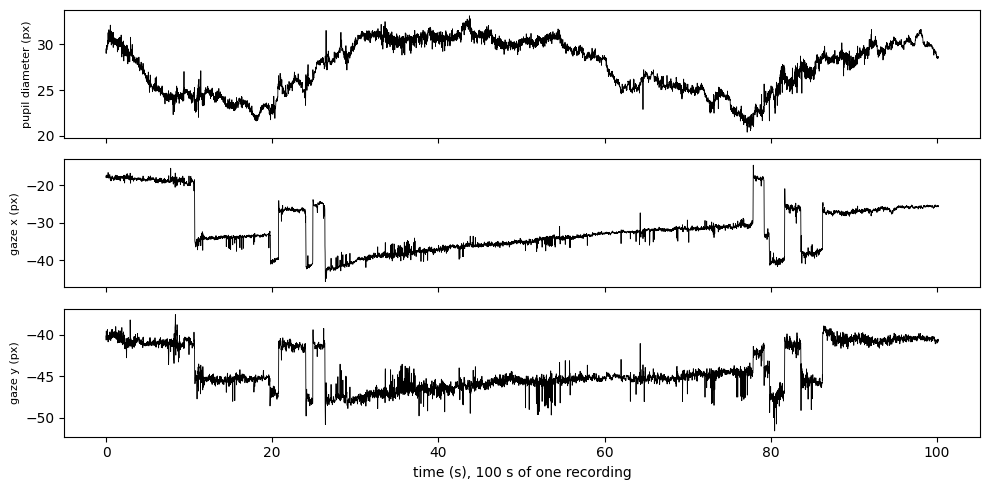

In [17]:
t0 = time.time(); pf0, pinfo0 = pupil_frames(rec0)
print(f"{len(pf0['size'])} video frames ({time.time()-t0:.0f} s to fetch; the per-frame ellipses are the slow part)"); print(pinfo0)
fig, ax = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
sl = slice(60000, 66000); tt = video_t0[sl] - video_t0[sl][0]
for a, k, lab in zip(ax, ["size", "gaze_x", "gaze_y"], ["pupil diameter (px)", "gaze x (px)", "gaze y (px)"]):
    a.plot(tt, pf0[k][sl], lw=0.6, color="k"); a.set_ylabel(lab, fontsize=8)
ax[-1].set_xlabel("time (s), 100 s of one recording"); plt.tight_layout(); plt.show()

### 8.4 Face motion

`roselab_facemap` holds Leon's FaceMap runs. His site runs (`facemap_paramset = 'leon_site_concat_2026'`,
`task_label = 'images'`) concatenate a site's videos so that each SVD component means the same on every day.
`FacialSignal.Trace` with `roi_no = 0` (the full frame) holds per FaceMap row the movie SVD (`mov_svd`), the motion SVD
(`mot_svd`, first 100 components stored) and the motion energy. The export uses components 0–9 of each, like Leon's.

In [18]:
# DEF: face motion
N_SVD = 10

def face_frames(seg):
    tr = (facemap.FacialSignal.Trace & seg & {"roi_no": 0}).fetch1()
    return dict(mov=np.asarray(tr["mov_svd"], float)[:, :N_SVD], mot=np.asarray(tr["mot_svd"], float)[:, :N_SVD],
                energy=np.asarray(tr["motion_energy"], float).ravel())

## 9. Stimulus images (files, not in the database)

The images are the only part of the export that is not in the database. They are 49,870 grayscale JPEGs (960 × 1280)
on the lab server, in
`/datajoint-data/data/leonk/analysis/texture_resources/natural_images/imagenet_MEI_grayscale_large_subset_stretch_warped/`.
Sorted by file name, image id *k* is the *k*-th file (`files[k − 1]`). The export stores channel 0 as a
`(1, 960, 1280)` `uint8` array. Set `IMAGE_DIR` if you have a copy elsewhere. Set `WRITE_IMAGES = False` to export
everything else (the run in this notebook does that: 4,900 images per recording are 6 GB).

In [19]:
# DEF: images
from PIL import Image
IMAGE_DIR = os.environ.get("DRIFT_IMAGE_DIR", "/datajoint-data/data/leonk/analysis/texture_resources/natural_images/"
                           "imagenet_MEI_grayscale_large_subset_stretch_warped")
WRITE_IMAGES = os.environ.get("DRIFT_WRITE_IMAGES", "1") == "1"
_IMAGE_FILES = None

def load_image(image_id):
    "(1, 960, 1280) uint8 array of one image id."
    global _IMAGE_FILES
    if _IMAGE_FILES is None:
        _IMAGE_FILES = sorted(f for f in os.listdir(IMAGE_DIR) if f.endswith(".jpg"))
    a = np.asarray(Image.open(os.path.join(IMAGE_DIR, _IMAGE_FILES[image_id - 1])))
    a = a[..., 2] if a.ndim == 3 else a          # channel 0 of OpenCV's BGR = blue; grayscale anyway
    return a[None].astype(np.uint8)

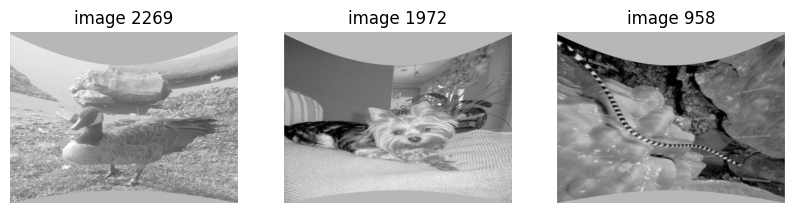

49870 image files


In [20]:
if os.access(IMAGE_DIR, os.R_OK):
    fig, ax = plt.subplots(1, 3, figsize=(10, 2.6))
    for a, i in zip(ax, tr0.image_id[:3]):
        a.imshow(load_image(int(i))[0], cmap="gray", vmin=0, vmax=255); a.set_title(f"image {i}"); a.axis("off")
    plt.show(); print(len(_IMAGE_FILES), "image files")
else:
    print("IMAGE_DIR not readable here: images will not be written")

## 10. Statistics and the folder tree

The data loader normalises with per-recording statistics (`max`, `mean`, `median`, `min`, `std`), stored in two
flavours as in Leon's export: `all` (every 2P frame of the recording) and `stimulus_frame` (only frames inside the
trial windows). Responses use the activity trace; behaviour and pupil use their 2P-frame series. Image statistics are
over the pixels of the shown images.

The tree, one folder per recording `<mouse>_<YYYY-MM-DD>_<scan_id>` (trial *i* = file `i.npy`):

```
config.json                              {"links": {}}
data/images/i.npy                        (1, 960, 1280) uint8
data/responses/i.npy                     (n_neurons,) float64
data/behavior/i.npy                      (24,) float32, columns as in section 8
data/pupil_center/i.npy                  (2,) pupil-glint vector, px
data/*/header.json                       what the files hold, with provenance
meta/trials/*.npy                        per trial: frame_image_id, tiers, frame_trial_ts, trial_idx, … (as Leon's)
meta/neurons/*.npy                       per neuron: unit_ids (mask), global_unit_ids (cell_index), coordinates, flags
meta/statistics/<data>/{all,stimulus_frame}/{max,mean,median,min,std}.npy
meta/export/pupil_flags.npz              trial_interp_frac
meta/export/eye.npz                      eye angles per trial (deg)
meta/export/provenance.json              every table, parameter and choice behind this folder
```

New beside Leon's files: `meta/neurons/cell_motor_coordinates_aligned.npy`, `roi_qc_rejected.npy`,
`tracked_in_all_sessions.npy`, `meta/export/eye.npz` and `meta/export/provenance.json`. `cell_motor_coordinates.npy` now holds the
recording's own ROI centres (Leon's held the registered ones, which are now in `…_aligned`), as the drift-model
requirements ask (`working-notes/rose-lab-export-requirements.md`, item 6).

In [21]:
# DEF: build one recording
STATS = {"max": np.nanmax, "mean": np.nanmean, "median": np.nanmedian, "min": np.nanmin, "std": np.nanstd}
BEHAVIOR_FIELDS = (["running_speed", "pupil_size", "pupil_size_derivative"]
                   + [f"face_movie_SVD_component_{j}" for j in range(N_SVD)]
                   + [f"face_motion_SVD_component_{j}" for j in range(N_SVD)] + ["face_motion_energy"])

def build_recording(mouse, rec, run_id, roi_group_ok=None, verbose=True):
    "Everything of one recording, as arrays in memory (nothing written)."
    t0 = time.time(); say = (lambda *a: print(f"  [{time.time()-t0:5.0f} s]", *a)) if verbose else (lambda *a: None)
    cur = latest_curation(rec); cells = cells_of(cur)
    ft = frame_times_2p(rec); tr = image_trials(rec, ft)
    n = int(tr.off_frame[0] - tr.on_frame[0] + 2)
    act = activity(cur)
    assert act.shape == (len(cells), len(ft)), (act.shape, len(cells), len(ft))
    rwin, bwin = window_index(tr.on_frame, RESPONSE_OFFSET, n), window_index(tr.on_frame, BEHAVIOR_OFFSET, n)
    assert rwin.max() < len(ft) and bwin.max() < len(ft)
    responses = act[:, rwin].mean(-1).T
    stim_frames = np.unique(bwin)                      # behaviour and pupil statistics: frames of the behaviour windows
    stats_resp = {"all": {k: f(act, axis=1) for k, f in STATS.items()},
                  "stimulus_frame": {k: f(act[:, rwin].reshape(len(cells), -1), axis=1) for k, f in STATS.items()}}
    del act; say("responses", responses.shape)
    gid, aligned, gsrc = global_ids(run_id, cur, cells, roi_group_ok)
    # behaviour, all as 2P-frame series
    run = running_speed(rec, ft); say("running")
    seg = face_segment(rec); row_t, video_t, cam = camera_times(seg)
    fm = face_frames(seg); say("face motion", cam["sync_method"])
    pf, pinfo = pupil_frames(rec); say("pupil")
    nv = min(len(pf["size"]), len(video_t)); vt = video_t[:nv]
    series = np.column_stack([run, to_2p(pf["size"][:nv], vt, ft), to_2p(pf["size_derivative"][:nv], vt, ft),
                              to_2p(fm["mov"], row_t, ft), to_2p(fm["mot"], row_t, ft), to_2p(fm["energy"], row_t, ft)])
    gaze = np.column_stack([to_2p(pf["gaze_x"][:nv], vt, ft), to_2p(pf["gaze_y"][:nv], vt, ft)])
    angles = (np.column_stack([to_2p(pf["azimuth"][:nv], vt, ft), to_2p(pf["elevation"][:nv], vt, ft)])
              if np.isfinite(pf["azimuth"]).any() else np.full((len(ft), 2), np.nan))
    interp = to_2p(pf["interpolated"][:nv], vt, ft)
    behavior_trials = series[bwin].mean(1).astype(np.float32)
    pupil_trials = gaze[bwin].mean(1)
    s = (session.Session * subject.Subject * subject.Line & {"session_id": rec["session_id"]}).fetch1()
    area = (scan.ScanLocation & {"session_id": rec["session_id"], "scan_id": rec["scan_id"]}).fetch1("anatomical_location")
    on, off = tr.on_frame.to_numpy(), tr.off_frame.to_numpy()
    pre_blank = np.r_[ft[on[0]], ft[on[1:]] - ft[off[:-1]]]   # first: time of the first onset frame (as Leon's)
    return dict(
        mouse=mouse, rec=rec, cur=cur, n=n, date=str(s["session_datetime"])[:10], line=s["line_name"], area=area,
        cells=cells, global_ids=gid, aligned=aligned, global_source=gsrc, cellreg_run_id=run_id,
        trials=tr, frame_trial_ts=ft[on], pre_blank=pre_blank, presentation=ft[off] - ft[on],
        responses=responses, behavior=behavior_trials, pupil_center=pupil_trials,
        trial_interp_frac=interp[bwin].mean(1), eye_angles=angles[bwin].mean(1),
        stats={"responses": stats_resp,
               "behavior": {"all": {k: f(series, axis=0).astype(np.float32) for k, f in STATS.items()},
                            "stimulus_frame": {k: f(series[stim_frames], axis=0).astype(np.float32) for k, f in STATS.items()}},
               "pupil_center": {"all": {k: f(gaze, axis=0) for k, f in STATS.items()},
                                "stimulus_frame": {k: f(gaze[stim_frames], axis=0) for k, f in STATS.items()}}},
        provenance=dict(camera=cam, pupil=pinfo, curation=cur, trace=TRACE, response_window=f"[on+{RESPONSE_OFFSET}, on+{RESPONSE_OFFSET}+n)",
                        behavior_window=f"[on+{BEHAVIOR_OFFSET}, on+{BEHAVIOR_OFFSET}+n)", n_frames_window=n,
                        running=f"wheel_pos angle, gradient x 59.84/360 cm/s, centred {RUNNING_BOX_S}-s box",
                        facemap=dict(paramset=FACEMAP_PARAMSET, task_label=FACEMAP_LABEL, roi_no=0, n_components=N_SVD),
                        cellreg=dict(cellreg_run_id=run_id, global_id_source=gsrc)))

In [22]:
# DEF: write one recording
def _save(path, arr):
    os.makedirs(os.path.dirname(path), exist_ok=True); np.save(path, arr)

def _json(path, obj):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

def write_recording(r, root, tracked=None, write_images=None):
    "Write one recording's folder; tracked = bool per neuron (cell present in every exported recording)."
    write_images = WRITE_IMAGES if write_images is None else write_images
    d = os.path.join(root, f"{r['mouse']}_{r['date']}_{r['rec']['scan_id']}")
    tr, cells, nn, nt = r["trials"], r["cells"], len(r["cells"]), len(r["trials"])
    _json(f"{d}/config.json", {"links": {}})
    img_stats = None
    if write_images and os.access(IMAGE_DIR, os.R_OK):
        acc = []
        for i, k in enumerate(tr.image_id):
            im = load_image(int(k)); _save(f"{d}/data/images/{i}.npy", im); acc.append(im.ravel()[::97])
        px = np.concatenate(acc).astype(float)
        img_stats = {k: f(px) for k, f in STATS.items()}
    for i in range(nt):
        _save(f"{d}/data/responses/{i}.npy", r["responses"][i])
        _save(f"{d}/data/behavior/{i}.npy", r["behavior"][i])
        _save(f"{d}/data/pupil_center/{i}.npy", r["pupil_center"][i])
    _json(f"{d}/data/responses/header.json", {"description": "Frame-averaged neuronal responses per trial (n_neurons,).",
          "n_neurons": nn, "trace_type": f"imaging.Activity.Trace, extraction_method={TRACE}",
          "averaging": f"mean over 2P frames {r['provenance']['response_window']}, n = {r['n']}"})
    _json(f"{d}/data/behavior/header.json", {"description": "Behaviour per trial, mean over the behaviour window (float32).",
          "window": r["provenance"]["behavior_window"], "fields": {str(i): f for i, f in enumerate(BEHAVIOR_FIELDS)},
          "units": {"running_speed": "cm/s", "pupil_size": "camera px (long axis)", "pupil_size_derivative": "px per camera frame"}})
    _json(f"{d}/data/pupil_center/header.json", {"description": "Pupil-glint vector per trial (px).", "coordinate_type": "pixel",
          "fields": {"0": "pupil_glint_x_px", "1": "pupil_glint_y_px"}, "source": r["provenance"]["pupil"],
          "interpolation_flags": "meta/export/pupil_flags.npz: trial_interp_frac",
          "eye_angles": "meta/export/eye.npz: eye_azimuth_deg, eye_elevation_deg per trial (set-12 3D eye model)"})
    _json(f"{d}/data/images/header.json", {"description": "Stimulus images.", "shape": "(n_channels, height, width)",
          "image_type": "stretch_warped", "color_format": "grayscale", "written": bool(img_stats)})
    # trials
    T = f"{d}/meta/trials"
    for name, arr in [("album", np.full(nt, "single", "U100")), ("animal_id", np.full(nt, r["mouse"], "U100")),
                      ("condition_hash", np.full(nt, "-1", "U100")),
                      ("frame_image_class", np.full(nt, "imagenet_grayscale_subset_stretch_warped", "U100")),
                      ("frame_image_id", tr.frame_image_id.to_numpy().astype(str)), ("frame_image_number", tr.image_id.to_numpy()),
                      ("frame_last_flip", np.full(nt, 69.0)), ("frame_pre_blank_period", r["pre_blank"]),
                      ("frame_presentation_time", r["presentation"]), ("frame_trial_ts", r["frame_trial_ts"]),
                      ("scan_idx", np.full(nt, r["rec"]["scan_id"])), ("session", np.full(nt, r["rec"]["session_id"], "U100")),
                      ("tiers", tr.tier.to_numpy().astype("U100")), ("trial_idx", np.arange(nt, dtype=float))]:
        _save(f"{T}/{name}.npy", arr)
    _json(f"{T}/header.json", {"n_trials": nt, "tier_definition": {"test": "image_id <= 100", "validation": "101-623", "train": "> 623"}})
    # neurons
    N = f"{d}/meta/neurons"
    tracked = np.zeros(nn, bool) if tracked is None else tracked
    for name, arr in [("animal_ids", np.full(nn, r["mouse"], "U100")), ("animal_strain", np.full(nn, r["line"], "U100")),
                      ("area", np.full(nn, r["area"], "U100")), ("layer", np.full(nn, "L2/3", "U100")),
                      ("scan_idx", np.full(nn, r["rec"]["scan_id"], "U100")), ("sessions", np.full(nn, r["rec"]["session_id"], "U100")),
                      ("unit_ids", cells["mask"].to_numpy()), ("global_unit_ids", r["global_ids"]),
                      ("cell_motor_coordinates", cells[["mask_center_x", "mask_center_y"]].to_numpy(float)),
                      ("cell_motor_coordinates_aligned", r["aligned"]), ("roi_qc_rejected", cells["roi_qc_rejected"].to_numpy()),
                      ("tracked_in_all_sessions", tracked)]:
        _save(f"{N}/{name}.npy", arr)
    _json(f"{N}/header.json", {"n_neurons": nn, "unit_ids": "Segmentation.Mask.mask (soma, latest curation)",
          "global_unit_ids": "CellReg cell_index (-1 = no cell)", "cellreg_run_id": r["cellreg_run_id"],
          "global_id_source": r["global_source"], "cell_motor_coordinates": "ROI centre in this recording (px)",
          "cell_motor_coordinates_aligned": "CellReg registered centroid (px, common frame of the site)"})
    # statistics
    S = f"{d}/meta/statistics"
    for kind in ("responses", "behavior", "pupil_center"):
        for flavour, vals in r["stats"][kind].items():
            for k, v in vals.items():
                _save(f"{S}/{kind}/{flavour}/{k}.npy", np.asarray(v))
    if img_stats:
        for flavour in ("all", "stimulus_frame"):
            for k, v in img_stats.items():
                _save(f"{S}/images/{flavour}/{k}.npy", np.asarray(v))
    os.makedirs(f"{d}/meta/export", exist_ok=True)
    np.savez(f"{d}/meta/export/pupil_flags.npz", trial_interp_frac=r["trial_interp_frac"])
    np.savez(f"{d}/meta/export/eye.npz", eye_azimuth_deg=r["eye_angles"][:, 0], eye_elevation_deg=r["eye_angles"][:, 1])
    _json(f"{d}/meta/export/provenance.json", dict(r["provenance"], exported=time.strftime("%Y-%m-%d %H:%M"),
          database_query_notebook="adamacs_ingest notebooks/23_drift_export_from_datajoint.ipynb"))
    return d

## 11. Export one recording, step by step

`build_recording` runs sections 4–8 for one recording and keeps the arrays in memory. `write_recording` writes the
folder. On this server one recording takes about 2.5 minutes; most of it is fetching 300,000 per-frame pupil ellipses.

In [23]:
EXPORT_ROOT = os.path.expanduser(os.environ.get("DRIFT_EXPORT_ROOT", "~/drift_export_rose"))
print("export root:", EXPORT_ROOT, "| write images:", WRITE_IMAGES)
r0 = build_recording("ROS-1841", rec0, run0)
print({k: (v.shape if hasattr(v, "shape") else v) for k, v in r0.items() if k in ("responses", "behavior", "pupil_center", "global_ids")})
pd.DataFrame(r0["behavior"], columns=BEHAVIOR_FIELDS).iloc[:, [0, 1, 2, 3, 13, 23]].describe().round(2)

export root: /home/backup_user/drift_export_rose | write images: False


  [    7 s] responses (4900, 667)


  [    8 s] running


  [   10 s] face motion camera_frames


  [  110 s] pupil


{'global_ids': (667,), 'responses': (4900, 667), 'behavior': (4900, 24), 'pupil_center': (4900, 2)}


,running_speed,pupil_size,pupil_size_derivative,face_movie_SVD_component_0,face_motion_SVD_component_0,face_motion_energy
count,4900.00,4900.00,4900.00,4900.00,4900.00,4900.00
mean,11.64,27.03,0.00,3429.87,325.17,3107579.75
std,11.80,2.59,0.03,4224.27,1822.40,1216031.88
min,-1.01,18.35,-0.22,-4806.89,-4022.74,224738.58
25%,0.12,25.33,-0.02,-488.57,-972.58,2285185.94
50%,8.60,27.27,-0.00,2874.21,871.00,3425629.62
75%,21.23,28.83,0.02,7235.35,1628.27,3969082.94
max,63.36,39.26,0.27,14459.65,4540.43,7107469.50


## 12. Export a whole mouse; tracked neurons

`export_mouse` builds every recording of a mouse, marks the neurons whose `cell_index` is present in **all** of the
mouse's recordings (`tracked_in_all_sessions`, the "global" neurons of the drift model; the others are "local"), and
writes the folders.

In [24]:
# DEF: export a mouse
def export_mouse(mouse, root=None, write=True, verbose=True):
    root = root or EXPORT_ROOT
    recs = recordings_of(mouse); run_id = cellreg_run(mouse)
    curs = [latest_curation(x) for x in recs]
    unresolved = [c for c in curs if run_members(run_id, c)[0] is None]
    rg_ok = roi_group_carries_run(run_id, curs) if unresolved else None
    if verbose:
        print(f"{mouse}: {len(recs)} recordings, CellReg run {run_id[:12]}, {len(unresolved)} unresolved column(s)"
              + (f", roi_group carries the run: {rg_ok}" if unresolved else ""))
    built = []
    for x in recs:
        if verbose: print(" ", x["scan_id"])
        built.append(build_recording(mouse, x, run_id, rg_ok, verbose=False))
    common = set.intersection(*[set(b["global_ids"][b["global_ids"] >= 0]) for b in built])
    folders = []
    for b in built:
        b["tracked"] = np.isin(b["global_ids"], list(common))
        if write:
            folders.append(write_recording(b, root, b["tracked"]))
    if verbose:
        print(f"  {len(common)} cells tracked in all {len(built)} recordings; neurons per recording:",
              [len(b["cells"]) for b in built])
    return built, folders

In [25]:
t0 = time.time()
built1841, folders1841 = export_mouse("ROS-1841")
print(f"{time.time()-t0:.0f} s; first folder: {os.path.basename(folders1841[0])}")
print(sorted(os.listdir(folders1841[0] + "/meta/neurons")))

ROS-1841: 11 recordings, CellReg run 8d7f5e3cb43e, 1 unresolved column(s), roi_group carries the run: True
  scan9FOWAIBH


  scan9FOXK90S


  scan9FOYO7M7


  scan9FOZV4RF


  scan9FP12UVN


  scan9FP28QH0


... (2 outputs left out)

  scan9FP5TKME


  scan9FP70H97


  scan9FP874OV


  103 cells tracked in all 11 recordings; neurons per recording: [667, 633, 654, 582, 621, 570, 594, 578, 539, 476, 440]
1234 s; first folder: ROS-1841_2024-07-01_scan9FOWAIBH
['animal_ids.npy', 'animal_strain.npy', 'area.npy', 'cell_motor_coordinates.npy', 'cell_motor_coordinates_aligned.npy', 'global_unit_ids.npy', 'header.json', 'layer.npy', 'roi_qc_rejected.npy', 'scan_idx.npy', 'sessions.npy', 'tracked_in_all_sessions.npy', 'unit_ids.npy']


## 13. Cross-check against Leon's export

Leon's export of the same recordings is on the lab server (`/datajoint-data/data/leonk/analysis/inception_loops_input`,
one folder per recording). For every ROS-1841 recording we compare each array:

* identical by construction: unit ids, global ids, image ids, tiers, trial times, responses;
* close: the aligned coordinates (the same CellReg centroids, stored rounded in the database);
* different on purpose: running (centred window, cm/s, behaviour window), pupil and gaze (rim fit set 12 and glint
  set 3 instead of the DLC-marker fit and the DLC glint). FaceMap is identical where the camera clock and window are
  the same; the correlation shows how much the window shift changes it.

In [26]:
# DEF: cross-check
LEON_EXPORT = os.environ.get("DRIFT_LEON_EXPORT", "/datajoint-data/data/leonk/analysis/inception_loops_input")

def compare_with_leon(b):
    d = os.path.join(LEON_EXPORT, f"{b['mouse']}_{b['date']}_{b['rec']['scan_id']}")
    L = lambda p: np.load(f"{d}/{p}", allow_pickle=True)
    nt = len(b["trials"])
    lr = np.stack([np.load(f"{d}/data/responses/{i}.npy") for i in range(nt)])
    lb = np.stack([np.load(f"{d}/data/behavior/{i}.npy") for i in range(nt)])
    lp = np.stack([np.load(f"{d}/data/pupil_center/{i}.npy") for i in range(nt)])
    lid = np.array([image_number(s) for s in L("meta/trials/frame_image_id.npy")])
    r = lambda x, y: float(np.corrcoef(x, y)[0, 1])
    lag = window_index(b["trials"].on_frame, 0, b["n"])      # Leon's behaviour window, for the FaceMap check
    return dict(
        scan=b["rec"]["scan_id"], trials=nt, neurons=len(b["cells"]),
        unit_ids=bool(np.array_equal(L("meta/neurons/unit_ids.npy"), b["cells"]["mask"])),
        global_ids=bool(np.array_equal(L("meta/neurons/global_unit_ids.npy"), b["global_ids"])), global_source=b["global_source"],
        coords_max_px=float(np.nanmax(np.abs(L("meta/neurons/cell_motor_coordinates.npy") - b["aligned"]))),
        image_ids=bool(np.array_equal(lid, b["trials"].image_id)), tiers=bool(np.array_equal(L("meta/trials/tiers.npy"), b["trials"].tier)),
        trial_ts=bool(np.allclose(L("meta/trials/frame_trial_ts.npy"), b["frame_trial_ts"])),
        responses_max_rel=float(np.abs(lr - b["responses"]).max() / np.abs(lr).max()),
        r_running=r(lb[:, 0], b["behavior"][:, 0]), r_pupil_size=r(lb[:, 1], b["behavior"][:, 1]),
        r_pupil_deriv=r(lb[:, 2], b["behavior"][:, 2]), r_face_mov0=r(lb[:, 3], b["behavior"][:, 3]),
        r_face_mot0=r(lb[:, 13], b["behavior"][:, 13]), r_energy=r(lb[:, 23], b["behavior"][:, 23]),
        r_gaze_x=r(lp[:, 0], b["pupil_center"][:, 0]), r_gaze_y=r(lp[:, 1], b["pupil_center"][:, 1]),
        camera=b["provenance"]["camera"]["sync_method"])

In [27]:
if os.access(LEON_EXPORT, os.R_OK):
    check = pd.DataFrame([compare_with_leon(b) for b in built1841]).set_index("scan")
    pd.set_option("display.width", 250); display(check.round(4))
else:
    print("Leon's export is not readable from here")

,trials,neurons,unit_ids,global_ids,global_source,coords_max_px,image_ids,tiers,trial_ts,responses_max_rel,r_running,r_pupil_size,r_pupil_deriv,r_face_mov0,r_face_mot0,r_energy,r_gaze_x,r_gaze_y,camera
scan,,,,,,,,,,,,,,,,,,,
scan9FOWAIBH,4900,667,True,True,cellreg_member,0.0005,True,True,True,0.0,0.8614,0.9851,0.4639,0.9959,0.9842,0.9854,0.9877,0.9241,camera_frames
scan9FOXK90S,4900,633,True,True,cellreg_member,0.0005,True,True,True,0.0,0.8341,0.9824,0.3738,0.9958,0.9799,0.9827,0.9871,0.8173,camera_frames
scan9FOYO7M7,4900,654,True,True,cellreg_member,0.0005,True,True,True,0.0,0.7893,0.9802,0.4573,0.9934,0.9759,0.9777,0.9887,0.8673,gate_rule
scan9FOZV4RF,4900,582,True,True,cellreg_member,0.0005,True,True,True,0.0,0.8041,0.9856,0.4236,0.9932,0.9770,0.9804,0.7263,0.8314,camera_frames
scan9FP12UVN,4900,621,True,True,cellreg_member,0.0005,True,True,True,0.0,0.8092,0.9763,0.4753,0.9939,0.9790,0.9801,0.9889,0.9209,camera_frames
scan9FP28QH0,4900,570,True,True,cellreg_member,0.0005,True,True,True,0.0,0.8627,0.9903,0.3529,0.9953,0.9812,0.9827,0.9755,0.9077,camera_frames
scan9FP3GJAU,4900,594,True,True,cellreg_member,0.0005,True,True,True,0.0,0.7931,0.9781,0.3671,0.9928,0.9789,0.9808,0.9841,0.7691,camera_frames
scan9FP4MQR4,4900,578,True,True,cellreg_member,0.0005,True,True,True,0.0,0.7795,0.9825,0.4167,0.9940,0.9748,0.9779,0.9786,0.8439,camera_frames
scan9FP5TKME,4900,539,True,True,roi_group,0.0005,True,True,True,0.0,0.8181,0.9783,0.4470,0.9942,0.9771,0.9808,0.9795,0.8363,camera_frames


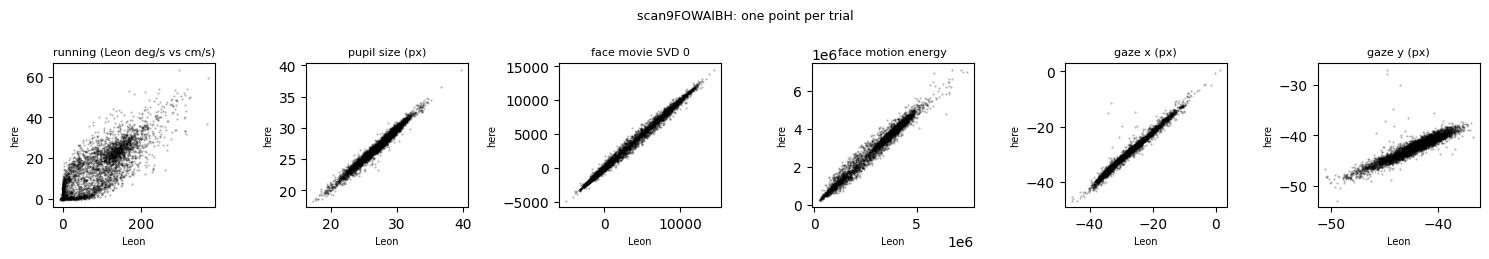

In [28]:
b = built1841[0]; d = os.path.join(LEON_EXPORT, f"{b['mouse']}_{b['date']}_{b['rec']['scan_id']}")
if os.access(d, os.R_OK):
    lb = np.stack([np.load(f"{d}/data/behavior/{i}.npy") for i in range(len(b["trials"]))])
    lp = np.stack([np.load(f"{d}/data/pupil_center/{i}.npy") for i in range(len(b["trials"]))])
    pairs = [(lb[:, 0], b["behavior"][:, 0], "running (Leon deg/s vs cm/s)"), (lb[:, 1], b["behavior"][:, 1], "pupil size (px)"),
             (lb[:, 3], b["behavior"][:, 3], "face movie SVD 0"), (lb[:, 23], b["behavior"][:, 23], "face motion energy"),
             (lp[:, 0], b["pupil_center"][:, 0], "gaze x (px)"), (lp[:, 1], b["pupil_center"][:, 1], "gaze y (px)")]
    fig, ax = plt.subplots(1, 6, figsize=(15, 2.6))
    for a, (x, y, lab) in zip(ax, pairs):
        a.plot(x, y, ".", ms=1, alpha=0.3, color="k"); a.set_title(lab, fontsize=8); a.set_xlabel("Leon", fontsize=7); a.set_ylabel("here", fontsize=7)
    plt.suptitle(f"{b['rec']['scan_id']}: one point per trial", fontsize=9); plt.tight_layout(); plt.show()

**Reading the table.** Unit ids, global ids, image ids, tiers and trial times are identical, and the responses agree to
float precision: the neural side of the export is Leon's.

The behaviour differs on purpose:
* **Running** correlates at r ≈ 0.8–0.9: the 2.5-s box is now centred instead of ahead of each sample, and the unit is
  cm/s instead of deg/s.
* **FaceMap** columns correlate below 1 only because the window starts 3 frames later. With his window they are
  identical (r = 1.000, checked when this notebook was written), except in recordings whose camera clock changed.
* **Pupil size** agrees at r ≈ 0.97–0.99. Here the rim fit and its outlier rejection replace his ellipse on the DLC
  markers.
* **The pupil–glint vector** changes most: the corrected glint (set 3, image detection) replaces the DLC `IR`
  marker. Across the cohort, x correlates at a median r = 0.97 and y at r = 0.83. In some mice y falls below 0.5
  (ROS-2210, ROS-2356, ROS-2359): there the DLC glint is noisy or jumps, which the image glint corrects (lab QC of
  2026-11-25: glint jumps > 40 px went from 18,338 frames to 36).

Where the camera clock changed (start-anchored, section 8.2: ROS-1881 scan9FPZHKKB and scan9FQ1UYJD, ROS-1912
scan9FQACAG8, ROS-2356 scan9G2HLHF1), FaceMap and pupil correlate lower. Leon's values there were 0.3–0.7 s
displaced; the new ones are on time.

## 14. Export all 11 mice

The same loop for the whole cohort. About 2.5 minutes per recording (117 recordings: ~5 h), plus the images if
written. It is not run in this notebook; set `RUN_ALL = True`, or run it as a script.

```python
for mouse in SITES:
    export_mouse(mouse)
```

Cross-check over all 117 recordings (run on 2026-11-27 with the code above, writing nothing):

| mouse | recordings | ids, tiers, times identical | responses max rel. diff | global id source | tracked in all | camera clock | r running | r pupil size | r face mov 0 | r gaze x / y |
|---|---|---|---|---|---|---|---|---|---|---|
| ROS-1841 | 11 | 11/11 | 0e+00 | run 10, roi_group 1 | 103 | events 10, gate rule 1 | 0.78–0.86 | 0.97–0.99 | 0.99–1.00 | 0.73–0.99 / 0.71–0.92 |
| ROS-1881 | 11 | 11/11 | 0e+00 | run 11 | 261 | events 8, start-anchored 2, gate rule 1 | 0.76–0.87 | 0.44–0.98 | 0.87–1.00 | 0.12–0.99 / 0.27–0.89 |
| ROS-1907 | 11 | 11/11 | 0e+00 | run 11 | 196 | events 11 | 0.66–0.96 | 0.95–0.99 | 0.99–1.00 | 0.90–0.99 / 0.55–0.93 |
| ROS-1912 | 11 | 11/11 | 0e+00 | run 11 | 119 | events 10, start-anchored 1 | 0.77–0.93 | 0.96–0.99 | 0.93–1.00 | 0.91–0.99 / 0.67–0.92 |
| ROS-1985 | 7 | 7/7 | 0e+00 | run 4, roi_group 3 | 276 | events 7 | 0.79–0.93 | 0.96–0.99 | 0.99–1.00 | 0.86–0.99 / 0.70–0.93 |
| ROS-2209 | 11 | 11/11 | 0e+00 | run, earlier curation† 11 | 248 | events 11 | 0.89–0.92 | 0.94–0.98 | 1.00–1.00 | 0.73–0.99 / 0.76–0.92 |
| ROS-2210 | 11 | 11/11 | 0e+00 | run, earlier curation† 11 | 149 | events 11 | 0.82–0.90 | 0.80–0.95 | 0.99–1.00 | 0.45–0.97 / -0.39–0.83 |
| ROS-2328 | 11 | 11/11 | 0e+00 | run 11 | 107 | events 11 | 0.79–0.94 | 0.94–0.99 | 0.98–1.00 | 0.81–0.98 / 0.78–0.96 |
| ROS-2356 | 11 | 11/11 | 0e+00 | run 10, run, earlier curation† 1 | 166 | gate rule 8, events 2, start-anchored 1 | 0.85–0.95 | 0.93–0.98 | 0.98–1.00 | 0.65–0.98 / 0.19–0.53 |
| ROS-2357 | 11 | 11/11 | 0e+00 | roi_group‡ 11 | 136 | gate rule 11 | 0.72–0.82 | 0.97–0.99 | 0.99–0.99 | 0.88–0.99 / 0.88–0.93 |
| ROS-2359 | 11 | 11/11 | 0e+00 | run 10, run, earlier curation† 1 | 288 | gate rule 8, events 3 | 0.76–0.93 | 0.95–0.99 | 0.99–0.99 | 0.50–0.99 / -0.14–0.94 |

† the run registered an earlier curation of the recording whose ROIs are pixel-identical (only the soma classification
changed later); checked in the database by `run_members`. ‡ `roi_group`, which the database cannot check for ROS-2357
(section 7). "ids, tiers, times identical": unit ids, global ids, image ids, tiers and trial times all equal Leon's.
"tracked in all" equals Leon's count of global neurons for every mouse. Correlations are over trials (4,900 per
recording), this export vs his. Gaze is NaN for ROS-2328 scan9G1OFAV9 (no glint, section 15).

In [29]:
RUN_ALL = False
if RUN_ALL:
    for mouse in SITES:
        export_mouse(mouse)

## 15. What is not in the database

Everything the export reads comes from the database, except these:

1. **Stimulus images.** 49,870 JPEG files (section 9); no table holds them or the id → file mapping.
2. **Glint for one recording.** `CorrectedGlint` set 3 was never computed for ROS-2328 scan9G1OFAV9. Its
   `pupil_center` (gaze) is NaN and flagged; pupil size, angles and everything else are exported. Populating set 3
   for this recording (about 20 minutes on the GPU worker) fills it.
3. **CellReg columns not tied to a curation** (`CellRegRun.UnresolvedColumn`):
   * ROS-1841 scan9FP5TKME: no curation matches the file's 1,280 centroids;
   * ROS-1985 scan9FS7YFS0 and scan9FS9553U: 9 curations match, holding 2 different mask sets; scan9FS3754E
     resolved to paramset 111 instead of 10;
   * ROS-2357, all 11: the resolver compared against `roi_group` and found no match.

   For these the export uses `roi_group`. It is checked against the run for ROS-1841 and ROS-1985; it cannot be
   checked in the database for ROS-2357, whose ids still equal Leon's exported ones. Re-resolving these columns in
   `roselab_cell_registration` would make every global id come from the run.
4. **Which CellReg run is the analysis run.** Nothing in the database marks it. The export picks the newest
   `<site>_Natural Images_CR` run by its result-file name; `StableCell` / `RoiGroupProjection` exist but are not
   used for these sites.
5. **The cohort.** Which 11 mice and sites form the curated data set is a list in this notebook, not a table.
6. **Rig geometry and eye-camera position** (drift-model requirements, items 13–14): viewing distance (11 cm), the
   50 × 50° warp, monitor size, and whether the eye camera was moved or refocused between sessions.
7. **The lab's eye-data rules** (sets 12/3, exclusions) and the camera-clock rule are written in code (here and in
   `v1audit.eye_rules`, `adamacs.schemas.facemap`); the database stores every option, not the choice.
8. **Grating responses for the same neurons** (requirements item 9) are in the database
   (`roselab_responsiveness`, keyed by the same curations and masks) but are not exported by this notebook yet.

## 16. Differences from Leon's export, in one table

| item | Leon (`inception_loops_input`) | this export | effect |
|---|---|---|---|
| neurons, responses, trials, tiers | DataJoint | the same queries | identical |
| `global_unit_ids` | `roi_group` at export time | CellReg run membership; `roi_group` only for unresolved columns | identical ids; ROS-2356/2359 would differ with today's `roi_group` |
| `cell_motor_coordinates` | CellReg registered centroid | own ROI centre; registered centroid in `…_aligned` | as the drift-model requirements ask |
| camera clock | gate rule (>150 unsaved → 121) | `FrameSync` rule (stored events → start anchor → gate rule) | 3 recordings shift by 0.3–0.7 s |
| FaceMap rows | his files | `FacialSignal`, 4-frame shift corrected in 15 segments | ROS-1912, ROS-2356 |
| pupil size, centre | cv2 ellipse on DLC markers, set-10 rejection | rim fit set 12 (v4.1) | r ≈ 0.98 (size) |
| glint | DLC `IR`, likelihood ≥ 0.9 | `CorrectedGlint` set 3, sources 1–2 | r ≈ 0.9–0.99 (gaze) |
| outlier rejection | set-10 acceptance on his DLC-marker fit | set-12 acceptance (rim, axis, temporal, spatial gate); rejected frames never used | — |
| eye angles | — | set-12 3D eye model, `meta/export/eye.npz` | new |
| running | box ahead of the sample, deg/s | centred box, cm/s | r ≈ 0.85; ×1/6.0 |
| behaviour window | `[on, on+n)` | `[on+3, on+3+n)` (`BEHAVIOR_OFFSET`) | matches the responses |
| ROI QC | — | `roi_qc_rejected` flag | no neuron removed |
| tracked neurons | computed downstream | `tracked_in_all_sessions` flag | — |
| provenance | headers | headers + `meta/export/provenance.json` | — |